# NLP Project: Disaster Tweet Classification

## 1. Project Introduction

### Problem Statement
The objective of this project is to develop a Natural Language Processing (NLP) model that classifies tweets into two categories: disaster-related and non-disaster-related.

### Project Objectives
- Explore and understand the tweet dataset.
- Clean and preprocess the text data.
- Convert text into numerical features.
- Train and compare machine learning classification models.
- Evaluate model performance using suitable metrics.
- Build a simple interface to predict the category of a tweet.

In [8]:
# ==================================================
# 2. IMPORTING REQUIRED LIBRARIES
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report 
print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
# ==================================================
# 3. LOADING THE DATASET
# ==================================================

import pandas as pd
df = pd.read_excel(r"C:\Users\USER\OneDrive\Desktop\disaster\twitter_disaster (1) (1) - Copy - Copy.xlsx")
print("Dataset loaded successfully!")

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five rows
df.head()


Dataset loaded successfully!
Dataset shape: (7613, 5)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [10]:
# 4. UNDERSTANDING THE DATASET

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-missing values
print("\nDataset information:")
df.info()

# Count missing values in each column
print("\nMissing values in each column:")
print(df.isnull().sum())

# Count completely duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (7613, 5)

Column names:
['id', 'keyword', 'location', 'text', 'target']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   str   
 2   location  5079 non-null   object
 3   text      7613 non-null   str   
 4   target    7613 non-null   int64 
dtypes: int64(2), object(1), str(2)
memory usage: 1.1+ MB

Missing values in each column:
id             0
keyword       61
location    2534
text           0
target         0
dtype: int64

Duplicate rows: 0


Target value counts:
target
0    4342
1    3271
Name: count, dtype: int64

Target percentages:
target
0    57.03
1    42.97
Name: proportion, dtype: float64


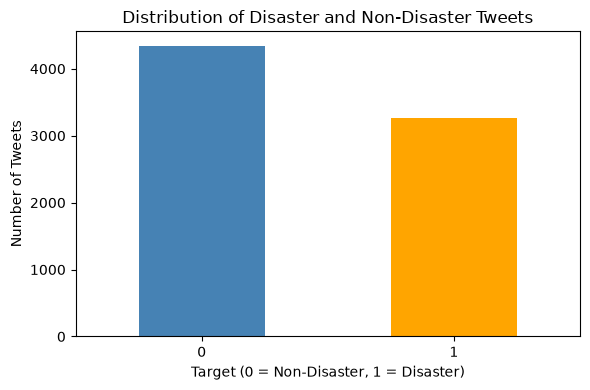

In [11]:
# 5. EXPLORATORY DATA ANALYSIS — TARGET DISTRIBUTION

# Count tweets in each target category
print("Target value counts:")
print(df["target"].value_counts().sort_index())

# Display the percentage of each category
print("\nTarget percentages:")
print((df["target"].value_counts(normalize=True).sort_index() * 100).round(2))

# Plot the number of tweets in each category
df["target"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6, 4),
    color=["steelblue", "orange"]
)

# Add chart title and labels
plt.title("Distribution of Disaster and Non-Disaster Tweets")
plt.xlabel("Target (0 = Non-Disaster, 1 = Disaster)")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [12]:
# 6. EXPLORING TWEET TEXT

# Display five non-disaster tweets
print("NON-DISASTER TWEETS (target = 0)")
display(df[df["target"] == 0][["text", "target"]].head())

# Display five disaster-related tweets
print("\nDISASTER TWEETS (target = 1)")
display(df[df["target"] == 1][["text", "target"]].head())

# Check the length of each tweet
df["text_length"] = df["text"].str.len()

# Display basic statistics about tweet length
print("\nTweet length statistics:")
print(df["text_length"].describe())


NON-DISASTER TWEETS (target = 0)


,text,target
15,What's up man?,0
16,I love fruits,0
17,Summer is lovely,0
18,My car is so fast,0
19,What a goooooooaaaaaal!!!!!!,0



DISASTER TWEETS (target = 1)


,text,target
0,Our Deeds are the Reason of this #earthquake M...,1
1,Forest fire near La Ronge Sask. Canada,1
2,All residents asked to 'shelter in place' are ...,1
3,"13,000 people receive #wildfires evacuation or...",1
4,Just got sent this photo from Ruby #Alaska as ...,1



Tweet length statistics:
count    7613.000000
mean      101.681203
std        34.352859
min         7.000000
25%        78.000000
50%       107.000000
75%       134.000000
max       190.000000
Name: text_length, dtype: float64


In [13]:
# 7. TEXT PREPROCESSING

import re

# Create a function to clean tweet text
def clean_tweet(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove mentions such as @username
    text = re.sub(r"@\w+", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Apply the cleaning function to each tweet
df["cleaned_text"] = df["text"].apply(clean_tweet)

# Compare original and cleaned tweets
display(df[["text", "cleaned_text", "target"]].head(10))


,text,cleaned_text,target
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this #earthquake m...,1
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask. canada,1
2,All residents asked to 'shelter in place' are ...,all residents asked to 'shelter in place' are ...,1
3,"13,000 people receive #wildfires evacuation or...","13,000 people receive #wildfires evacuation or...",1
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby #alaska as ...,1
5,#RockyFire Update => California Hwy. 20 closed...,#rockyfire update => california hwy. 20 closed...,1
6,#flood #disaster Heavy rain causes flash flood...,#flood #disaster heavy rain causes flash flood...,1
7,I'm on top of the hill and I can see a fire in...,i'm on top of the hill and i can see a fire in...,1
8,There's an emergency evacuation happening now ...,there's an emergency evacuation happening now ...,1
9,I'm afraid that the tornado is coming to our a...,i'm afraid that the tornado is coming to our a...,1


In [14]:
# 8. TF-IDF FEATURE EXTRACTION

from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Convert cleaned tweets into numerical features
X = tfidf.fit_transform(df["cleaned_text"])

# Store the target labels
y = df["target"]

# Display the dimensions of the feature matrix
print("TF-IDF matrix shape:", X.shape)

# Display a few words learned by the vectorizer
print("\nFirst 20 features:")
print(tfidf.get_feature_names_out()[:20])


TF-IDF matrix shape: (7613, 5000)

First 20 features:
['00' '000' '01' '02' '03' '04' '05' '06' '06jst' '07' '08' '087809233445'
 '09' '0l' '10' '100' '1000' '101' '1023' '103']


In [15]:
# 9. SPLITTING DATA INTO TRAINING AND TESTING SETS

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Separate the input text and target labels
X_text = df["cleaned_text"]
y = df["target"]

# Split the data: 80% training and 20% testing
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit TF-IDF on training text only
tfidf = TfidfVectorizer(max_features=5000)
X_train = tfidf.fit_transform(X_train_text)

# Transform testing text using the same fitted vectorizer
X_test = tfidf.transform(X_test_text)

# Display the sizes of the datasets
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)


Training samples: 6090
Testing samples: 1523
Training feature matrix: (6090, 5000)
Testing feature matrix: (1523, 5000)


In [16]:
# 10. MODEL TRAINING — LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model using the training data
model.fit(X_train, y_train)

# Predict the labels for the test data
y_pred = model.predict(X_test)

# Display a success message
print("Model training completed successfully!")

# Display a few actual and predicted labels
print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

Model training completed successfully!

First 10 actual labels:
[0, 0, 1, 0, 0, 1, 1, 1, 0, 0]


Model Accuracy: 81.68%

Classification Report:
              precision    recall  f1-score   support

Non-Disaster       0.81      0.89      0.85       869
    Disaster       0.83      0.72      0.77       654

    accuracy                           0.82      1523
   macro avg       0.82      0.80      0.81      1523
weighted avg       0.82      0.82      0.81      1523


Confusion Matrix:
[[775  94]
 [185 469]]


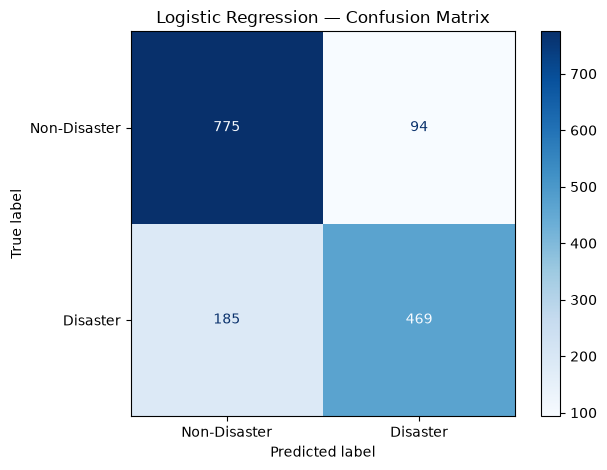

In [17]:

# 11. MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2%}")

# Display precision, recall, F1-score, and support
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Disaster", "Disaster"]
))

# Calculate and display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Plot the confusion matrix
display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Disaster", "Disaster"]
)

display_plot.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()


In [18]:
# 12. MODEL IMPROVEMENT — BALANCED LOGISTIC REGRESSION

# Import the model and evaluation metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create a second model with balanced class weights
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the improved model
balanced_model.fit(X_train, y_train)

# Predict the test labels
balanced_pred = balanced_model.predict(X_test)

# Evaluate the improved model
print("Balanced Model Accuracy:",
      f"{accuracy_score(y_test, balanced_pred):.2%}")

print("\nBalanced Model Classification Report:")
print(classification_report(
    y_test,
    balanced_pred,
    target_names=["Non-Disaster", "Disaster"]
))

# Display the confusion matrix
print("\nBalanced Model Confusion Matrix:")
print(confusion_matrix(y_test, balanced_pred))


Balanced Model Accuracy: 80.37%

Balanced Model Classification Report:
              precision    recall  f1-score   support

Non-Disaster       0.83      0.83      0.83       869
    Disaster       0.77      0.78      0.77       654

    accuracy                           0.80      1523
   macro avg       0.80      0.80      0.80      1523
weighted avg       0.80      0.80      0.80      1523


Balanced Model Confusion Matrix:
[[717 152]
 [147 507]]


In [19]:
# 13. MODEL COMPARISON

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Calculate evaluation metrics for the original model
original_results = {
    "Model": "Original Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Disaster Precision": precision_score(y_test, y_pred, pos_label=1),
    "Disaster Recall": recall_score(y_test, y_pred, pos_label=1),
    "Disaster F1-Score": f1_score(y_test, y_pred, pos_label=1)
}

# Calculate evaluation metrics for the balanced model
balanced_results = {
    "Model": "Balanced Logistic Regression",
    "Accuracy": accuracy_score(y_test, balanced_pred),
    "Disaster Precision": precision_score(y_test, balanced_pred, pos_label=1),
    "Disaster Recall": recall_score(y_test, balanced_pred, pos_label=1),
    "Disaster F1-Score": f1_score(y_test, balanced_pred, pos_label=1)
}

# Create and display the comparison table
comparison_df = pd.DataFrame([original_results, balanced_results])

# Display the comparison table without special formatting
display(comparison_df.round(4))



,Model,Accuracy,Disaster Precision,Disaster Recall,Disaster F1-Score
0,Original Logistic Regression,0.8168,0.8330,0.7171,0.7707
1,Balanced Logistic Regression,0.8037,0.7693,0.7752,0.7723


In [20]:
# 14. TESTING THE MODEL ON NEW TWEETS

# Create sample tweets for testing
sample_tweets = [
    "There is a massive earthquake in the city",
    "I love spending time with my family",
    "Forest fire is spreading near residential areas",
    "Today is a beautiful and sunny day"
]

# Clean the sample tweets
cleaned_samples = [clean_tweet(tweet) for tweet in sample_tweets]

# Convert the cleaned tweets using the fitted TF-IDF vectorizer
sample_features = tfidf.transform(cleaned_samples)

# Predict using the balanced model
sample_predictions = balanced_model.predict(sample_features)

# Display each tweet and its prediction
for tweet, prediction in zip(sample_tweets, sample_predictions):
    if prediction == 1:
        label = "Disaster-related"
    else:
        label = "Non-disaster"

    print("Tweet:", tweet)
    print("Prediction:", label)
    print("-" * 60)


Tweet: There is a massive earthquake in the city
Prediction: Disaster-related
------------------------------------------------------------
Tweet: I love spending time with my family
Prediction: Non-disaster
------------------------------------------------------------
Tweet: Forest fire is spreading near residential areas
Prediction: Disaster-related
------------------------------------------------------------
Tweet: Today is a beautiful and sunny day
Prediction: Non-disaster
------------------------------------------------------------


In [21]:
# 15. SAVING THE TRAINED MODEL

import joblib
from pathlib import Path

# Create a folder to store the model files
model_folder = Path("models")
model_folder.mkdir(exist_ok=True)

# Save the balanced Logistic Regression model
joblib.dump(
    balanced_model,
    model_folder / "disaster_tweet_model.pkl"
)

# Save the fitted TF-IDF vectorizer
joblib.dump(
    tfidf,
    model_folder / "tfidf_vectorizer.pkl"
)

print("Model and TF-IDF vectorizer saved successfully!")
print("Model folder:", model_folder.resolve())
print("Files saved:")
print("- disaster_tweet_model.pkl")
print("- tfidf_vectorizer.pkl")


Model and TF-IDF vectorizer saved successfully!
Model folder: C:\Users\USER\Documents\Codex\2026-09-26\h\outputs\disaster_tweet_project\models
Files saved:
- disaster_tweet_model.pkl
- tfidf_vectorizer.pkl


In [22]:

# Step 1: Train and evaluate a Linear SVM model

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create the model
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=3000
)

# Train using the TF-IDF training data
svm_model.fit(X_train, y_train)

# Predict using the TF-IDF test data
svm_predictions = svm_model.predict(X_test)

# Evaluate the model
print("LINEAR SVM MODEL RESULTS")
print("------------------------")

print(
    "Accuracy:",
    round(accuracy_score(y_test, svm_predictions) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        svm_predictions,
        target_names=["Non-disaster", "Disaster"]
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))


LINEAR SVM MODEL RESULTS
------------------------
Accuracy: 78.4 %

Classification Report:
              precision    recall  f1-score   support

Non-disaster       0.82      0.80      0.81       869
    Disaster       0.74      0.76      0.75       654

    accuracy                           0.78      1523
   macro avg       0.78      0.78      0.78      1523
weighted avg       0.78      0.78      0.78      1523

Confusion Matrix:
[[698 171]
 [158 496]]


In [23]:

# Step 2: Examine incorrect predictions from Linear SVM

# Combine actual labels and predictions for comparison
results = pd.DataFrame({
    "text": X_test_text.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": svm_predictions
})

# Keep only incorrectly classified tweets
errors = results[results["actual"] != results["predicted"]]

print("Total incorrect predictions:", len(errors))
print("\nFirst 10 incorrect predictions:")

for _, row in errors.head(10).iterrows():
    actual_label = "Disaster" if row["actual"] == 1 else "Non-disaster"
    predicted_label = (
        "Disaster" if row["predicted"] == 1 else "Non-disaster"
    )

    print("\nTweet:", row["text"])
    print("Actual:", actual_label)
    print("Predicted:", predicted_label)


Total incorrect predictions: 329

First 10 incorrect predictions:

Tweet: step one: get that mass murderer's portrait off the yuan.
Actual: Non-disaster
Predicted: Disaster

Tweet: hollywood movie about trapped miners released in chile: 'the 33' hollywood movie about trapped miners starring...
Actual: Disaster
Predicted: Non-disaster

Tweet: i can't drown my demons they know how to swim
Actual: Disaster
Predicted: Non-disaster

Tweet: rip the world... its burning
Actual: Non-disaster
Predicted: Disaster

Tweet: we need these plants in the pacific during the cyclone seasons it would help
Actual: Disaster
Predicted: Non-disaster

Tweet: if firefighters acted like cops they'd drive around shooting a flamethrower at burning buildings
Actual: Non-disaster
Predicted: Disaster

Tweet: ignition knock (detonation) sensor-senso standard ks57
Actual: Non-disaster
Predicted: Disaster

Tweet: maybe we should call israel and tell them we're sorry are pres has sold them down the river to annihilation

In [24]:

# Step 3: Count the two types of classification errors

false_positives = results[
    (results["actual"] == 0) &
    (results["predicted"] == 1)
]

false_negatives = results[
    (results["actual"] == 1) &
    (results["predicted"] == 0)
]

print("FALSE POSITIVES:", len(false_positives))
print("Ordinary tweets incorrectly classified as disasters")

print("\nFALSE NEGATIVES:", len(false_negatives))
print("Disaster tweets incorrectly classified as non-disasters")

print("\nExamples of false negatives:")
for tweet in false_negatives["text"].head(5):
    print("-", tweet)

print("\nExamples of false positives:")
for tweet in false_positives["text"].head(5):
    print("-", tweet)


FALSE POSITIVES: 171
Ordinary tweets incorrectly classified as disasters

FALSE NEGATIVES: 158
Disaster tweets incorrectly classified as non-disasters

Examples of false negatives:
- hollywood movie about trapped miners released in chile: 'the 33' hollywood movie about trapped miners starring...
- i can't drown my demons they know how to swim
- we need these plants in the pacific during the cyclone seasons it would help
- i agree with certain cultural appropriation things but honestly if u looked at my house it screams appropriation bc buddhas and stuff-
- the dress memes have officially exploded on the internet

Examples of false positives:
- step one: get that mass murderer's portrait off the yuan.
- rip the world... its burning
- if firefighters acted like cops they'd drive around shooting a flamethrower at burning buildings
- ignition knock (detonation) sensor-senso standard ks57
- maybe we should call israel and tell them we're sorry are pres has sold them down the river to annihi

In [25]:

# Step 4: Compare all three classification models

model_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression",
        "Linear SVM"
    ],
    "Accuracy (%)": [81.68, 80.37, 78.40],
    "Disaster Precision": [0.8330, 0.7693, 0.74],
    "Disaster Recall": [0.7171, 0.7752, 0.76],
    "Disaster F1-score": [0.7707, 0.7723, 0.75]
})

display(model_comparison.round(4))


,Model,Accuracy (%),Disaster Precision,Disaster Recall,Disaster F1-score
0,Original Logistic Regression,81.68,0.8330,0.7171,0.7707
1,Balanced Logistic Regression,80.37,0.7693,0.7752,0.7723
2,Linear SVM,78.40,0.7400,0.7600,0.7500


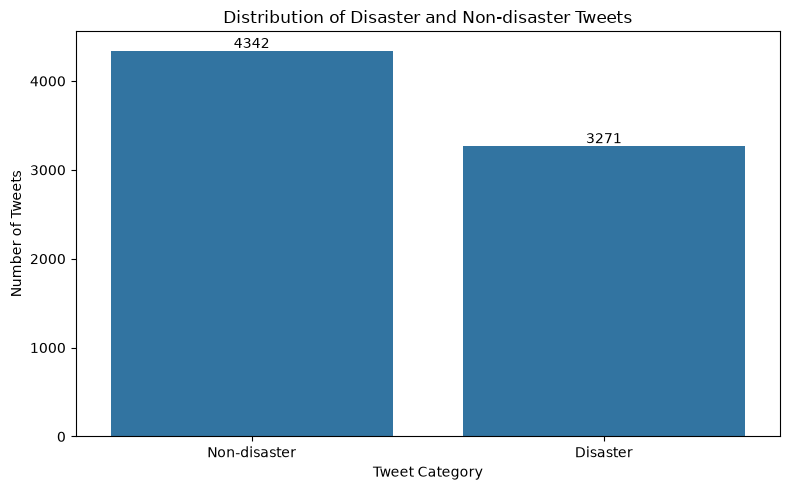

In [26]:

# Step: Visualize disaster and non-disaster tweets

import matplotlib.pyplot as plt
import seaborn as sns

# Count the two classes in the target column
class_counts = df["target"].value_counts().sort_index()

# Create readable labels
class_counts.index = ["Non-disaster", "Disaster"]

# Draw the bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Distribution of Disaster and Non-disaster Tweets")
plt.xlabel("Tweet Category")
plt.ylabel("Number of Tweets")

# Display the number above each bar
for i, count in enumerate(class_counts.values):
    plt.text(i, count + 30, str(count), ha="center")

plt.tight_layout()
plt.show()


Top 15 words in disaster-related tweets:
http: 2382
the: 1361
and: 505
for: 401
from: 245
that: 209
with: 192
this: 182
after: 181
fire: 180
was: 169
are: 166
you: 142
have: 142
news: 140


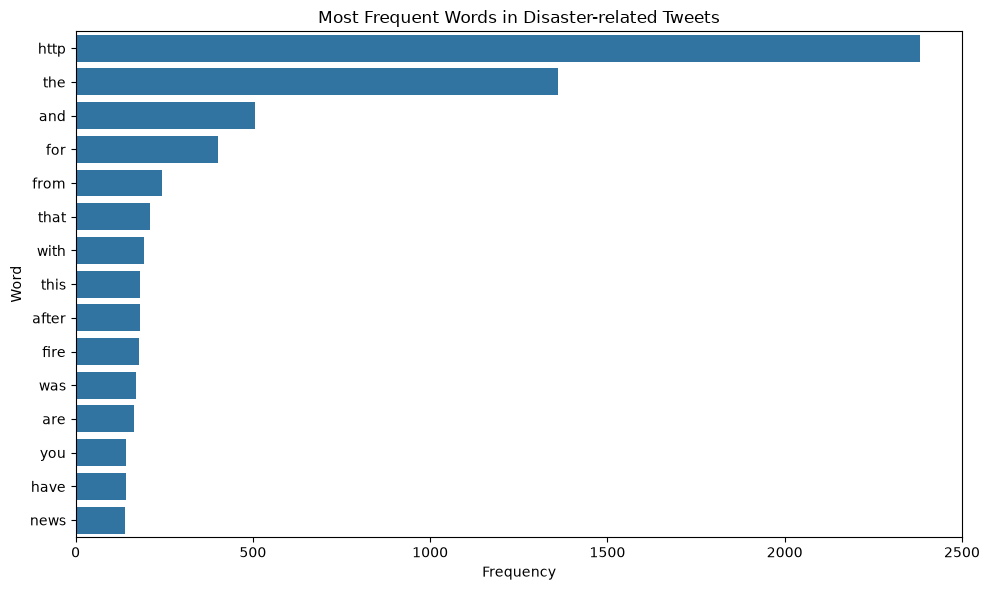

In [27]:

# Step: Find the most frequent keywords in disaster tweets

from collections import Counter
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Select tweets labelled as disasters
disaster_tweets = df.loc[df["target"] == 1, "text"].dropna()

# Combine the disaster tweets into one text string
all_disaster_text = " ".join(disaster_tweets.astype(str)).lower()

# Extract words and count their frequency
words = re.findall(r"\b[a-z]{3,}\b", all_disaster_text)

word_counts = Counter(words)

# Display the 15 most frequent words
top_words = word_counts.most_common(15)

print("Top 15 words in disaster-related tweets:")
for word, count in top_words:
    print(f"{word}: {count}")

# Plot the results
words_df = pd.DataFrame(top_words, columns=["Word", "Frequency"])

plt.figure(figsize=(10, 6))
sns.barplot(
    data=words_df,
    x="Frequency",
    y="Word"
)

plt.title("Most Frequent Words in Disaster-related Tweets")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


Top 15 meaningful words in disaster-related tweets:
news: 140
amp: 135
disaster: 121
california: 115
suicide: 112
police: 109
people: 105
killed: 95
like: 94
hiroshima: 91
just: 89
storm: 89
fires: 86
crash: 85
families: 81


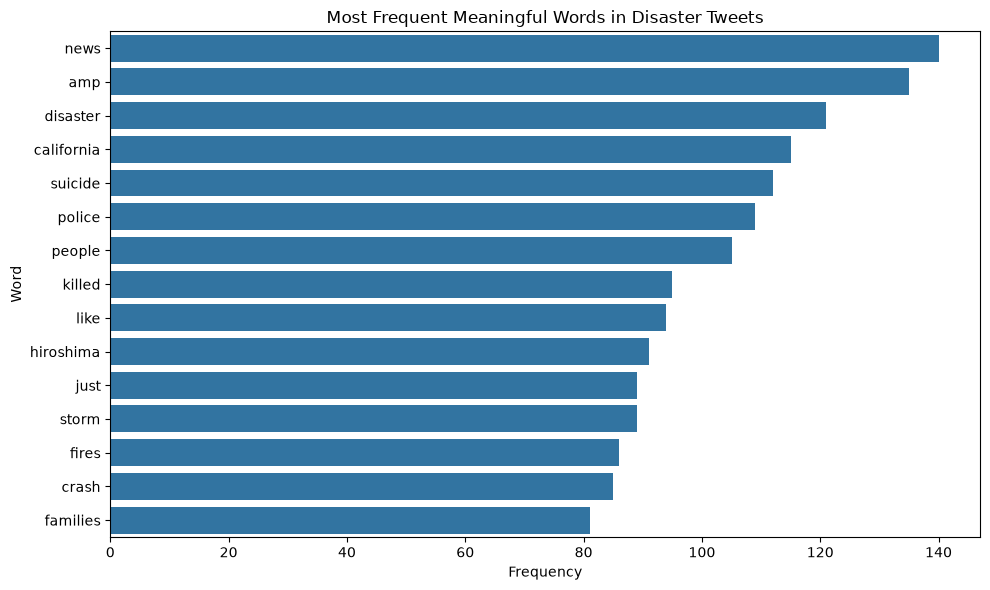

In [28]:

# Improved keyword frequency analysis
# Remove URLs and common English words

from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select disaster-related tweets
disaster_tweets = df.loc[df["target"] == 1, "text"].dropna()

# Combine tweets and convert to lowercase
all_text = " ".join(disaster_tweets.astype(str)).lower()

# Remove URLs
all_text = re.sub(r"https?://\S+|www\.\S+", " ", all_text)

# Extract words
words = re.findall(r"\b[a-z]{3,}\b", all_text)

# Remove common English stop words
meaningful_words = [
    word for word in words
    if word not in ENGLISH_STOP_WORDS
]

# Count the most frequent remaining words
top_words = Counter(meaningful_words).most_common(15)

# Display the results
print("Top 15 meaningful words in disaster-related tweets:")
for word, count in top_words:
    print(f"{word}: {count}")

# Plot the results
words_df = pd.DataFrame(
    top_words,
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(10, 6))
sns.barplot(data=words_df, x="Frequency", y="Word")
plt.title("Most Frequent Meaningful Words in Disaster Tweets")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


In [29]:

# Compare frequent meaningful words in both classes

from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def get_top_words(tweets, top_n=15):
    # Combine tweets and convert to lowercase
    text = " ".join(tweets.dropna().astype(str)).lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Extract words
    words = re.findall(r"\b[a-z]{3,}\b", text)

    # Remove common English words
    words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS
    ]

    return Counter(words).most_common(top_n)


# Get words for each class
disaster_words = get_top_words(
    df.loc[df["target"] == 1, "text"]
)

non_disaster_words = get_top_words(
    df.loc[df["target"] == 0, "text"]
)

# Prepare a comparison table
comparison_df = pd.DataFrame({
    "Disaster words": pd.Series(dict(disaster_words)),
    "Non-disaster words": pd.Series(dict(non_disaster_words))
}).fillna(0).astype(int)

display(comparison_df)


,Disaster words,Non-disaster words
amp,135,209
body,0,116
california,115,0
crash,85,0
day,0,86
disaster,121,0
don,0,127
emergency,0,81
families,81,0
fires,86,0


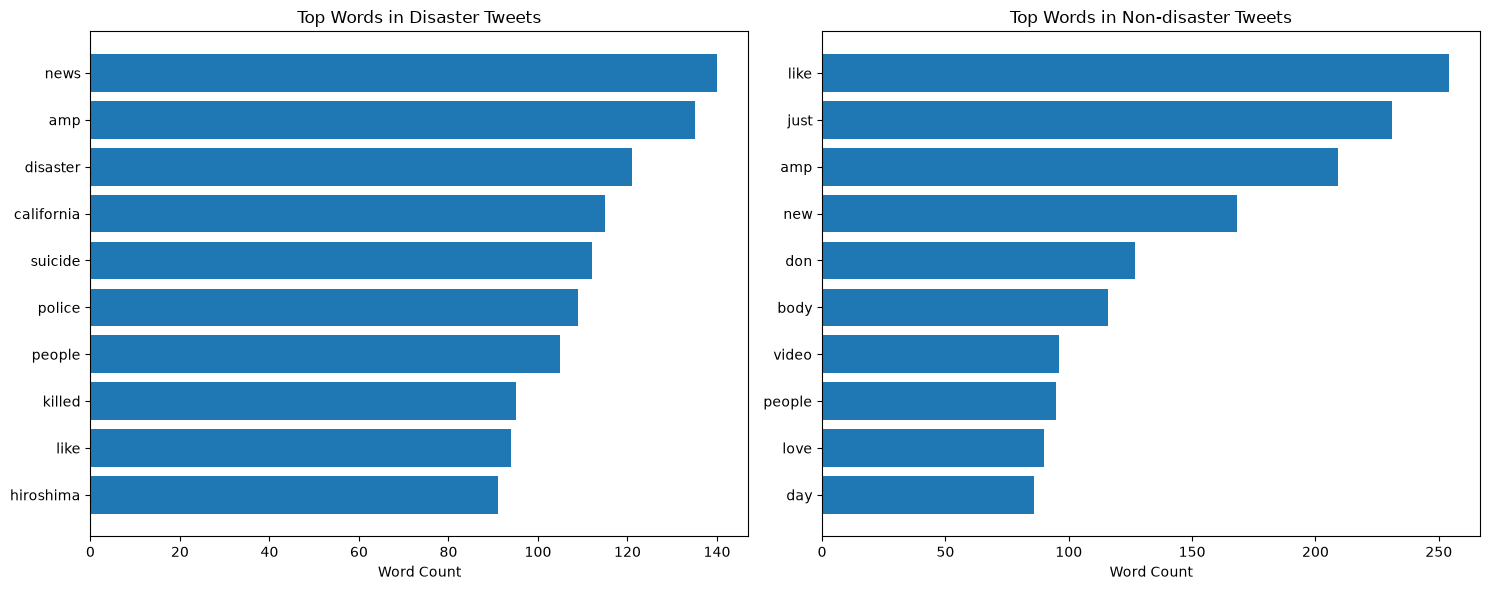

In [33]:

# Visualize the top 10 words in each class

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Disaster-related tweets
axes[0].barh(
    [word for word, count in disaster_words[:10]][::-1],
    [count for word, count in disaster_words[:10]][::-1]
)
axes[0].set_title("Top Words in Disaster Tweets")
axes[0].set_xlabel("Word Count")

# Non-disaster tweets
axes[1].barh(
    [word for word, count in non_disaster_words[:10]][::-1],
    [count for word, count in non_disaster_words[:10]][::-1]
)
axes[1].set_title("Top Words in Non-disaster Tweets")
axes[1].set_xlabel("Word Count")

plt.tight_layout()
plt.show()


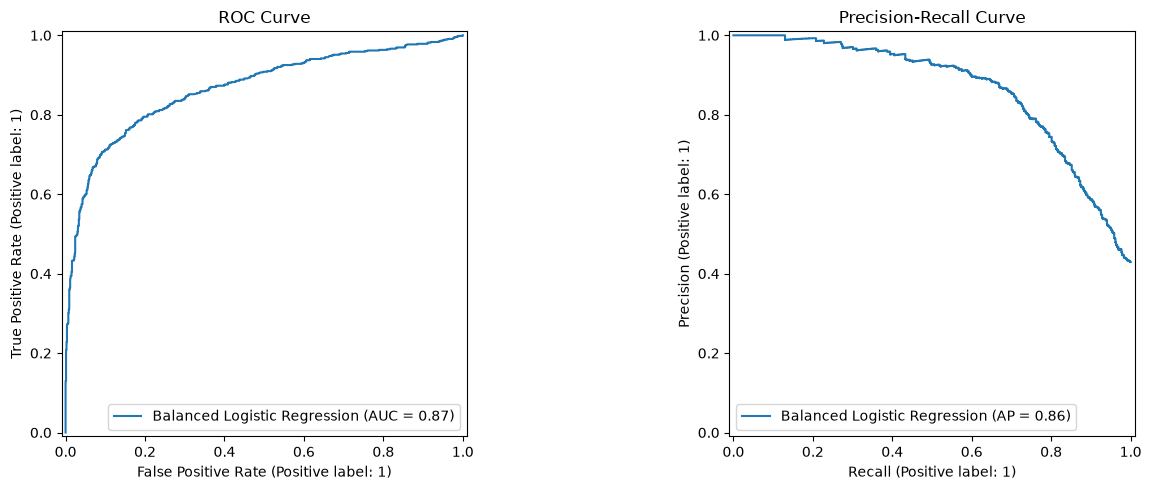

ROC-AUC Score: 0.867
Average Precision Score: 0.8647


In [32]:

# Step: ROC Curve and Precision-Recall Curve

import matplotlib.pyplot as plt

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay,
    roc_auc_score,
    average_precision_score
)

# Get prediction scores from the balanced Logistic Regression model
y_scores = balanced_model.predict_proba(X_test)[:, 1]

# Create two evaluation curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_scores,
    ax=axes[0],
    name="Balanced Logistic Regression"
)
axes[0].set_title("ROC Curve")

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_scores,
    ax=axes[1],
    name="Balanced Logistic Regression"
)
axes[1].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

# Print evaluation scores
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_scores), 4))
print(
    "Average Precision Score:",
    round(average_precision_score(y_test, y_scores), 4)
)
